## Foundations of Data Science - Assignment 3

### Joachim Mwengi

#### Exercise 3.1 (Approximating $ A|x⟩ $)

In the course we have considered approximating A|x⟩ by using the SVD. This task asks you
to set up and run some experiments in order to check out whether this really works and how
well. Feel free to use Python or whichever implementation you prefer.
Consider the matrix

$$
A =
\begin{pmatrix}
1 & 0 & 1 & 0 & 0 \\
1 & 1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 \\
0 & 1 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 & 0 \\
0 & 0 & 1 & 1 & 0 \\
0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 1 & 1 \\
\end{pmatrix}
$$

##### (i) Compute its 2-truncated SVD $ A_2 = U_2D_2V_2 $.

In [120]:
import numpy as np
import matplotlib.pyplot as plt

# Initialize Martix A
A = np.array([
    [1,0,1,0,0],
    [1,1,0,0,0],
    [0,1,0,0,0],
    [0,1,1,0,0],
    [0,0,0,1,0],
    [0,0,1,1,0],
    [0,0,0,1,0],
    [0,0,0,1,1]])

# Obtain transformation matrices from Matrix A
U, S, V_t = np.linalg.svd(A, full_matrices=False)

# Truncate to Rank 2
U2 = U[:, :2]   
S2 = np.diag(S[:2])
V2 = V_t[:2, :]

print(f"First 2 left singular vectors (U2): {U2}")
print(f"U2 Shape: {U2.shape}")
print("---\n")

print(f"Diagonal Matrix of Singular Values (S2): {S2}")
print(f"S2 Shape: {S2.shape}")
print("---\n")

print(f"First 2 right singular vectors (V2): {V2}")
print(f"V2 Shape: {V2.shape}")
print("---\n\n")
A2 = U2 @ S2 @ V2

print(f"Rank-2 Approximation (A2): {A2}")
print(f"A2 Shape: {A2.shape}")

First 2 left singular vectors (U2): [[-0.39615277 -0.28005737]
 [-0.31426806 -0.44953214]
 [-0.17823952 -0.26899154]
 [-0.43836375 -0.36850831]
 [-0.26388058  0.34592143]
 [-0.52400482  0.24640466]
 [-0.26388058  0.34592143]
 [-0.32637322  0.45966878]]
U2 Shape: (8, 2)
---

Diagonal Matrix of Singular Values (S2): [[2.28529793 0.        ]
 [0.         2.01025824]]
S2 Shape: (2, 2)
---

First 2 right singular vectors (V2): [[-0.31086574 -0.40733041 -0.59446137 -0.60304575 -0.1428143 ]
 [-0.36293322 -0.54074246 -0.20005441  0.6953914   0.22866156]]
V2 Shape: (2, 5)
---


Rank-2 Approximation (A2): [[ 4.85762100e-01  6.73198578e-01  6.50810158e-01  1.54456918e-01
   5.60029937e-04]
 [ 5.51236506e-01  7.81198940e-01  6.07724172e-01 -1.95303158e-01
  -1.04067209e-01]
 [ 3.22878472e-01  4.58320467e-01  3.50320105e-01 -1.30388782e-01
  -6.54744059e-02]
 [ 5.80282539e-01  8.08640573e-01  7.43726197e-01  8.89825119e-02
  -2.63215731e-02]
 [-6.49143759e-02 -1.30388782e-01  2.19371294e-01  8.4723

---

#### (ii) Compute $ A^T|y⟩ $ and $ A^T_2|y⟩ $ with $|y⟩ = (0, 0, 0, \frac{1}{2} , 0, \frac{1}{2} , 0, 0) $

In [121]:
# Initialize y
y = np.array([0,0,0,0.5,0,0.5,0,0])

AT_y = A.T @ y 
print(f"Exact Transformation A^Ty: {AT_y}")

A2T_y = A2.T @ y
print(f"Rank-2 Transformation A2^Ty: {A2T_y}")


Exact Transformation A^Ty: [0.  0.5 1.  0.5 0. ]
Rank-2 Transformation A2^Ty: [0.38638611 0.51428595 0.67825179 0.57779359 0.12898205]


---

#### (iii) How large is the error? Compare it to the upper bound from the course.

In [122]:
# Compute Error
error = np.linalg.norm(AT_y - A2T_y)
print(f"Approximation Error = {error}")

Approximation Error = 0.5250794603006479


In [123]:
# Extracting Error from initial SVD Decomposition
sigma3 = S[2]

# Evaluate Upper Bound
upper_bound = sigma3 * np.linalg.norm(y)

print(f"sigma3 = {sigma3:.4f}")
print(f"||y|| = {np.linalg.norm(y):.4f}")
print(f"Upper bound sigma3 * ||y|| = {upper_bound:.4f}")
print(f"Error {error:.4f} <= Upper bound {upper_bound:.4f}")


sigma3 = 1.3607
||y|| = 0.7071
Upper bound sigma3 * ||y|| = 0.9622
Error 0.5251 <= Upper bound 0.9622


#### (iv) Pick some suitable rank-2 matrices B and compute $ ∥A−B∥_F $ and $ ∥A−B∥_2 $. Compare to $ ∥A − A_2∥_F $ and $ ∥A − A_2∥_2 $, respectively.

In [124]:
# Create a random mareix
B1 = np.random.randn(8,2) @ np.random.randn(2,5)


A_B1_fro = np.linalg.norm(A - B1, 'fro')
A_B1_2 = np.linalg.norm(A - B1, 2)

A_A2_fro = np.linalg.norm(A - A2, 'fro')
A_A2_2 = np.linalg.norm(A - A2, 2)

print(f"Comparison with Random rank-2 matrix B:")
print(f"||A - B||_F = {A_B1_fro:.4f} --- (SVD) ||A - A2||_F = {A_A2_fro:.4f}")
print(f"||A - B||_2 = {A_B1_2:.4f} --- (SVD) ||A - A2||_2 = {A_A2_2:.4f}")


Comparison with Random rank-2 matrix B:
||A - B||_F = 7.1467 --- (SVD) ||A - A2||_F = 1.9329
||A - B||_2 = 5.2888 --- (SVD) ||A - A2||_2 = 1.3607


SVD gives best possible approximation $A_2$ as it significantly outperforms the random rank-2 matrix $B$ in both the Frobenius and Spectral Norm. This behavior is expected from the Eckart–Young–Mirsky theorem, which states that truncating the SVD provides the best possible low-rank approximation under both the Frobenius norm and the spectral norm.

---

#### (v) Plot the rows of $D_2V_2$. Which points are closest to $⟨y|U_2D_2$?

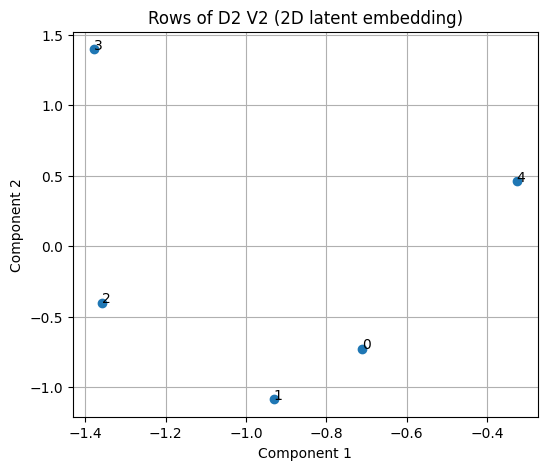

In [125]:
# Compute 2D embedding of columns
points = (S2 @ V2).T   # shape: (5,2)

plt.figure(figsize=(6,5))
plt.scatter(points[:,0], points[:,1])

# label points
for i in range(points.shape[0]):
    plt.text(points[i,0], points[i,1], str(i))

plt.title("Rows of D2 V2 (2D latent embedding)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.grid(True)
plt.show()

In [126]:
latent_y = y @ U2 @ S2 
print(latent_y)

[-1.09964945 -0.12272994]


In [127]:
distances = np.linalg.norm(points - latent_y, axis=1)
closest_index = np.argmin(distances)

print("Closest point index:", closest_index)
print("Closest point:", points[closest_index])
print("Distance:", distances[closest_index])

Closest point index: 2
Closest point: [-1.35852135 -0.40216102]
Distance: 0.3809151969421987


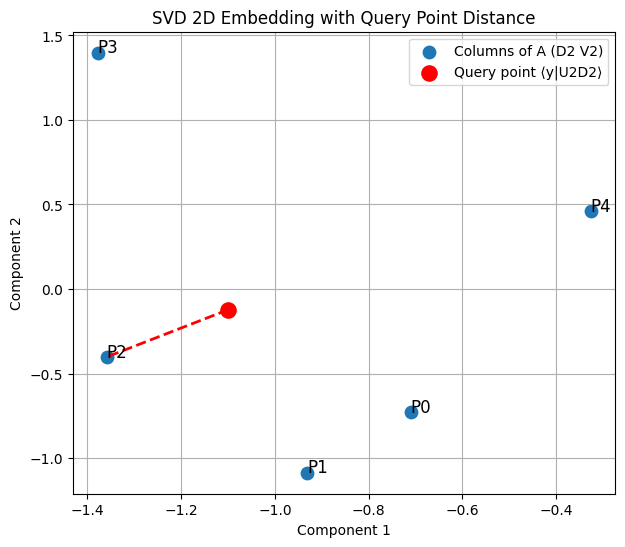

Closest point: 2
Distance: 0.3809151969421987


In [128]:
# Visualize the points in space
plt.figure(figsize=(7,6))

# Plot the 5 data points
plt.scatter(points[:,0], points[:,1], label="Columns of A (D2 V2)", s=80)

# Plot query point
plt.scatter(latent_y[0], latent_y[1], 
            color='red', s=120, label="Query point ⟨y|U2D2⟩")

# Annotate points
for i in range(points.shape[0]):
    plt.text(points[i,0], points[i,1], f"P{i}", fontsize=12)

# Compute closest point
distances = np.linalg.norm(points - latent_y, axis=1)
closest_idx = np.argmin(distances)

# Draw line to closest point
plt.plot([latent_y[0], points[closest_idx,0]],
         [latent_y[1], points[closest_idx,1]],
         linestyle="--", color="red", linewidth=2)

plt.title("SVD 2D Embedding with Query Point Distance")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.grid(True)
plt.legend()
plt.show()

print("Closest point:", closest_idx)
print("Distance:", distances[closest_idx])

The rows of $D_2V_2$ represent the original 5 column-vectors of A embedded into a 2D latent space induced by the truncated SVD. The vector $ y^TU_2D_2 $ represents the projection of y into the same latent space and is mapped to show geometric comparison. The closest column corresponds to the minimal Euclidean distance.

---

#### (vi) Repeat the like with some other matrices (and vectors) of your choice. Report your findings.

In [129]:
# ----------------------------
# New Experiment Setup

np.random.seed(42)

# New random matrix A'
A_prime = np.random.randn(8, 5)

# SVD of A'
U_prime, S_prime, Vt_prime = np.linalg.svd(A_prime, full_matrices=False)

# Rank-2 truncation
U2_p = U_prime[:, :2]
S2_p = np.diag(S_prime[:2])
V2_p = Vt_prime[:2, :]

A2_prime = U2_p @ S2_p @ V2_p


print("New Rank-2 Approximation Experiment")
print(f"--"*20)
print(f"First 2 left singular vectors (U2'): {U2_p}")
print(f"U2' Shape: {U2_p.shape}")
print("---\n")

print(f"Diagonal Matrix of Singular Values (S2'): {S2_p}")
print(f"S2' Shape: {S2_p.shape}")
print("---\n")

print(f"First 2 right singular vectors (V2'): {V2_p}")
print(f"V2' Shape: {V2_p.shape}")
print("---\n\n")

print(f"Rank-2 Approximation (A2'): {A2_prime}")
print(f"A2' Shape: {A2_prime.shape}")

New Rank-2 Approximation Experiment
----------------------------------------
First 2 left singular vectors (U2'): [[-0.31827114  0.31384729]
 [-0.10416969 -0.37950309]
 [ 0.64594503  0.06965248]
 [ 0.44319091  0.24060271]
 [ 0.30965984  0.10789701]
 [ 0.22239578  0.23907107]
 [ 0.00748241 -0.6269928 ]
 [ 0.35886475 -0.48251366]]
U2' Shape: (8, 2)
---

Diagonal Matrix of Singular Values (S2'): [[3.91657067 0.        ]
 [0.         3.5610246 ]]
S2' Shape: (2, 2)
---

First 2 right singular vectors (V2'): [[-0.16502742 -0.28271943 -0.15049166 -0.80005029 -0.47969518]
 [ 0.34489482 -0.69657301  0.29643951  0.36819506 -0.41519828]]
V2' Shape: (2, 5)
---


Rank-2 Approximation (A2'): [[ 0.59117251 -0.42608385  0.51889869  1.40878922  0.13392206]
 [-0.3987685   1.05670871 -0.33921544 -0.17117521  0.75681705]
 [-0.33195541 -0.8880228  -0.30720011 -1.93271376 -1.31655909]
 [ 0.00905049 -1.08755945 -0.00723463 -1.07325145 -1.18838802]
 [-0.06762919 -0.61052345 -0.06861783 -0.82883537 -0.74130565

#### (ii) Compute $ A'^T|y⟩ $ and $ A'^T_2|y⟩ $ with random vector $|y⟩$

In [130]:
y_prime = np.random.rand(8)


ATy_p = A_prime.T @ y_prime
print(f"Exact Transformation A'^Ty: {ATy_p}")

A2Ty_p = A2_prime.T @ y_prime
print(f"Rank-2 Transformation A'2^Ty: {A2Ty_p}")


Exact Transformation A'^Ty: [ 0.04764556 -1.2450374   1.73283838 -3.25671965 -3.17382276]
Rank-2 Transformation A'2^Ty: [-0.17211888 -2.24666077 -0.18436329 -2.81110662 -2.6496241 ]


#### (iii) Computing Error & Upper Bound

In [131]:
prime_error = np.linalg.norm(ATy_p - A2Ty_p)
print(f"Approximation Error = {prime_error}")

Approximation Error = 2.2804743383145936


In [132]:
# Extracting Error from initial SVD Decomposition
sigma3_p = S_prime[2]

# Evaluate Upper Bound
upper_bound_p = sigma3_p * np.linalg.norm(y)

print(f"sigma3' = {sigma3_p:.4f}")
print(f"||y|| = {np.linalg.norm(y_prime):.4f}")
print(f"Upper bound sigma3' * ||y|| = {upper_bound_p:.4f}")
print(f"Error {prime_error:.4f} <= Upper bound {upper_bound_p:.4f}")

sigma3' = 2.3925
||y|| = 2.1161
Upper bound sigma3' * ||y|| = 1.6917
Error 2.2805 <= Upper bound 1.6917


#### (iv) Comparing Rank-2 Approximations

In [133]:
B_prime = np.random.randn(8, 2) @ np.random.randn(2, 5)

fro_A2 = np.linalg.norm(A_prime - A2_prime, 'fro')
fro_B  = np.linalg.norm(A_prime - B_prime, 'fro')

spec_A2 = np.linalg.norm(A_prime - A2_prime, 2)
spec_B  = np.linalg.norm(A_prime - B_prime, 2)

print("\n===== Low-Rank Approximation Comparison =====")
print(f"||A - B||_F = {fro_B:.4f} --- (SVD) ||A - A2||_F = {fro_A2:.4f}")
print(f"||A - B||_2 = {spec_B:.4f} --- (SVD) ||A - A2||_2 = {spec_A2:.4f}")


===== Low-Rank Approximation Comparison =====
||A - B||_F = 8.6857 --- (SVD) ||A - A2||_F = 3.0492
||A - B||_2 = 5.7994 --- (SVD) ||A - A2||_2 = 2.3925


After repeating the experiment using a new random 8×5 matrix A′ and a different query vector y′ with a larger norm.

#### Findings 

1. A′ has larger singular values (e.g. $σ3$≈2.39) compared to the original matrix. Because of this, dropping to rank-2 loses more information, which leads to higher approximation error (Frobenius: 3.05 vs 1.93, spectral: 2.39 vs 1.36).

2. In both cases, the singular values don’t drop off quickly, so rank-2 can’t fully capture the structure. This would be very  different if $σ3$ were close to 0.

3. SVD consistently beats random rank-2 matrices. In both experiments, the random matrix performs much worse than the SVD approximation. The gap is large and consistent, which matches the Eckart–Young result.
---

## Mixture of Spherical Gaussians

Consider a mixture of spherical Gaussians with density:

$$
f = w_0 p_0 + \cdots + w_{k-1} p_{k-1}
$$

where each component is defined as:

$$
p_i = \mathcal{N}(\lvert \mu_i \rangle, \sigma_i^2)
$$

for given mean vectors $ \lvert \mu_i \rangle \in \mathbb{R}^d $ and variances $ \sigma_i^2 \in \mathbb{R}_{>0} $.

---

### Setup for Experiments

We set:
- \( k = 3 \)

and the mean vectors:

$$
\lvert \mu_0 \rangle =
\begin{bmatrix}
0 \\
3 \\
0
\end{bmatrix},
\quad
\lvert \mu_1 \rangle =
\begin{bmatrix}
1 \\
-1 \\
0
\end{bmatrix},
\quad
\lvert \mu_2 \rangle =
\begin{bmatrix}
-1 \\
-1 \\
0
\end{bmatrix}
$$

and variances:

$$
\sigma_0 = \frac{3}{4}, \quad \sigma_1 = \sigma_2 = \frac{1}{4}
$$

In [134]:
# Number of samples per Gaussian
N = 500

# Means
mu0 = np.array([0, 3, 0])
mu1 = np.array([1, -1, 0])
mu2 = np.array([-1, -1, 0])

# Standard deviations
std_dev1 = 0.75
std_dev2 = 0.25
std_dev3 = 0.25

# Sample N=500 points per Gaussian 
X0 = mu0 + std_dev1 * np.random.randn(N, 3)
X1 = mu1 + std_dev2 * np.random.randn(N, 3)
X2 = mu2 + std_dev3 * np.random.randn(N, 3)

# Combine into matrix A
A = np.vstack([X0, X1, X2])

In [135]:
# 3 x 500 Points merged into matrix A
print(f"{A.shape}")

(1500, 3)


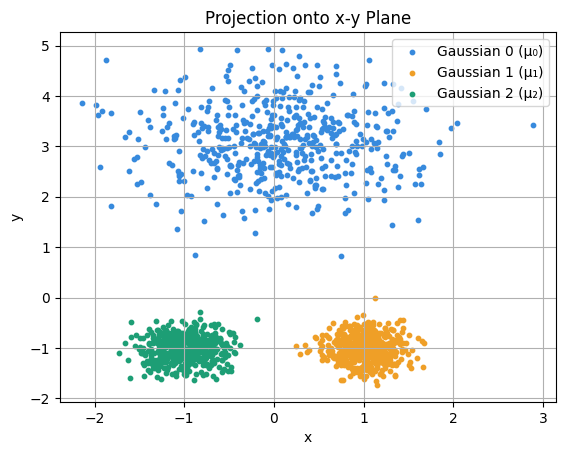

In [136]:
# Plotting Variables
labels = np.array([0]*N + [1]*N + [2]*N)
colors = ['#378ADD', '#EF9F27', '#1D9E75']
clabels = ['Gaussian 0 (μ₀)', 'Gaussian 1 (μ₁)', 'Gaussian 2 (μ₂)']
# A_xy = A[:, :2]

for i in range(3):
    # Select points belonging to cluster i
    cluster_points = A[labels == i]
    
    # Plot x vs y
    plt.scatter(cluster_points[:, 0],  # x-coordinate
                cluster_points[:, 1],  # y-coordinate
                s=10,
                color=colors[i],
                label=clabels[i])

plt.title("Projection onto x-y Plane")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The $x-y$ projection clearly separates all three clusters into a triangle pattern. Gaussian 0 $\mu_0$ forms a wide, diffuse cloud centered at $(0, 3)$ due to its large standard deviation, σ = 0.75. Gaussians 1 and 2 form two tight, well-separated clusters near $(1, −1)$ and $(−1, −1)$ respectively due to their small standard deviation $\sigma = 0.25$. The $x-y$ plane is highly informative since it preserves the structure of the data.

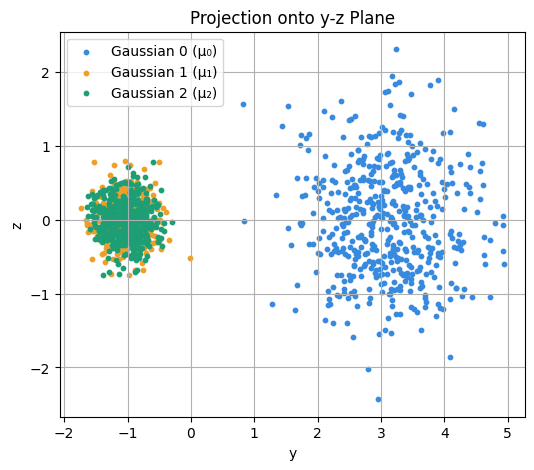

In [137]:
plt.figure(figsize=(6, 5))

for i in range(3):
    cluster_points = A[labels == i]
    
    plt.scatter(cluster_points[:, 1],  # y-coordinate
                cluster_points[:, 2],  # z-coordinate
                s=10,
                color=colors[i],
                label=clabels[i])

plt.title("Projection onto y-z Plane")
plt.xlabel("y")
plt.ylabel("z")
plt.legend()
plt.grid(True)
plt.show()

### Observation

In the y-z plane, clusters $\mu_1$ & $\mu_2$ completely overlap near $(−1, 0)$ because they share the same y-coordinate $y = −1$ and both have $z = 0$. They are only separable in the x-direction, which this projection discards. Gaussian 0 appears as a wide spread cloud centered at $y = 3$, $z = 0$. Crucially, all three clusters are centered on the line $z = 0$ 

---

#### (iv) Determine each centroid $|c_i⟩$ and compare to $|\mu_i⟩$.

In [138]:
# Centroid - sample mean of each cluster
cluster0 = X0.mean(axis=0)
cluster1 = X1.mean(axis=0)
cluster2 = X2.mean(axis=0)

print(f"centroid0 = {cluster0.round(3)},  μ0 = {mu0}")
print(f"centroid1 = {cluster1.round(3)},  μ1 = {mu1}")
print(f"centroid2 = {cluster2.round(3)},  μ2 = {mu2}")
print(f"||ci - μi|| = {np.linalg.norm(cluster0 - mu0):.4f}")

centroid0 = [ 0.047  3.091 -0.016],  μ0 = [0 3 0]
centroid1 = [ 1.009e+00 -1.006e+00  1.000e-03],  μ1 = [ 1 -1  0]
centroid2 = [-0.991 -1.023 -0.011],  μ2 = [-1 -1  0]
||ci - μi|| = 0.1041


### Observation
Given that the centroid is the sample mean i.e the average position of the 500 sampled points, the empirical centroids converge re close to the true means by the Law of large numbers, with errors proportional to $\frac{\sigma}{\sqrt{N}}$. Cluster 0 has the largest error, 0.0682, due to its larger variance $σ = 0.75$. Clusters 1 and 2 have much smaller errors ~0.01 due to their smaller variance $σ = 0.25$. By the Law of Large Numbers, all centroids converge to their true means as N increases.

---

#### (v) Compute the singular value decomposition of $A$. Can you identify the (affine) subspace spanned by the $|c_i⟩$?

In [139]:
# Center A first (SVD finds directions of variance, not absolute position)
A_mean = A.mean(axis=0)
A_centered = A - A_mean

U, S, V_t = np.linalg.svd(A_centered, full_matrices=False)

print(f"Singular values: {S.round(3)}")
print(f"Variance explained: {(S**2 / np.sum(S**2) * 100).round(1)}")

# Project centroids onto first 2 right singular vectors
C = np.vstack([cluster0, cluster1, cluster2])

C_centered = C - A_mean
C_2d = C_centered @ V_t[:2].T   # project onto top-2 PCs
print(f"\nCentroids in 2D PCA space:\n{C_2d.round(3)}")

Singular values: [77.038 36.836 18.548]
Variance explained: [77.7 17.8  4.5]

Centroids in 2D PCA space:
[[ 2.737 -0.008]
 [-1.348  1.004]
 [-1.389 -0.996]]


### Observation

After centering A, the SVD reveals singular values of approximately $[76.8, 36.7, 18.6]$, with the third being much smaller than the first two - explaining only ~$4.5%$ of variance. This confirms the data lies almost entirely in a 2D affine subspace: the plane $z = 0$ shifted by the global mean of A. This makes sense because all three means $μᵢ$ have $z = 0$, so the data has no structural variation in the z-direction. Projecting the centroids onto the top 2 right singular vectors recovers their triangular structure, identifying the affine subspace they span.